# Drawing interaction nets

A test of drawing `inets` nets in a notebook, in the style of Lafont's figures. With Graphviz's `dot` installed, the pictures are
made locally; in JupyterLite, viz.js (Graphviz compiled to WebAssembly) draws them in the page.

In [1]:
try:
    import inets
except ImportError:
    %pip install -q inets
    import inets
print(inets.__version__)

0.1.3


In [2]:
import json
import shutil
import subprocess
import uuid
from collections import deque

from IPython.display import HTML, SVG
from inets.net import _FREE, Port

VIZ = "https://cdn.jsdelivr.net/npm/@viz-js/viz@3.31.0/+esm"
DRAW_UP_TO = 80  # nodes: larger nets are described, not drawn (as in the inets kernel)

# Grain and ragged ink: noise displaces the strokes a little, then speckles of paper eat
# into the ink, then what is left is thickened slightly, as toner spreads.
RETRO = """<defs><filter id="retro" x="-5%" y="-5%" width="110%" height="110%">
<feTurbulence type="fractalNoise" baseFrequency="0.7" numOctaves="2" seed="3" result="warp"/>
<feDisplacementMap in="SourceGraphic" in2="warp" scale="2.2" xChannelSelector="R" yChannelSelector="G" result="ragged"/>
<feTurbulence type="fractalNoise" baseFrequency="1.6" numOctaves="1" seed="9" result="grain"/>
<feColorMatrix in="grain" type="matrix" values="0 0 0 0 0  0 0 0 0 0  0 0 0 0 0  0 0 0 -14 8.6" result="holes"/>
<feComposite in="ragged" in2="holes" operator="in" result="speckled"/>
<feMorphology in="speckled" operator="dilate" radius="0.45" result="spread"/>
<feComponentTransfer in="spread"><feFuncA type="discrete" tableValues="0 1 1 1"/></feComponentTransfer>
</filter></defs>"""


def _arity(net, n):
    kind = net.kind[n]
    return 0 if kind == _FREE else net.system.agents[kind].arity


def _outputs(net, named):
    """The named free ports joined to a port signed ``+``, in a table with signs."""
    out = []
    for n in named:
        q = net.link.get(Port(n, 0))
        if q is None or net.kind[q.node] == _FREE:
            continue
        signs = net.system.agents[net.kind[q.node]].signs
        if signs is not None and signs[q.index] == "+":
            out.append(n)
    return out


def lafont_dot(net, names=None, top=None):
    """The net as Graphviz text, drawn as in Lafont's figures."""
    names = {Port(*p).node: label for p, label in (names or {}).items()}
    tops = [Port(*p).node for p in top] if top is not None else (_outputs(net, names) or list(names)[:1])
    # Breadth first from the top ports together, then from whatever is left: a node's
    # depth is its rank, and each wire runs down from the node that reached it.
    order, depth = [], {}
    for starts in [tops] + [[n] for n in list(names) + sorted(net.kind)]:
        starts = [n for n in starts if n not in depth]
        if not starts:
            continue
        for n in starts:
            depth[n] = 0
        queue = deque(starts)
        while queue:
            n = queue.popleft()
            order.append(n)
            for i in range(_arity(net, n) + 1):
                q = net.link.get(Port(n, i))
                if q is not None and q.node not in depth:
                    depth[q.node] = depth[n] + 1
                    queue.append(q.node)
    out = [
        "graph net {",
        '  graph [nodesep=0.25, ranksep=0.3, ordering=out, splines=line, bgcolor="transparent"];',
        '  node [shape=ellipse, fontname="Helvetica", fontsize=14, margin="0.06,0.02",'
        ' width=0, height=0, penwidth=1.3];',
        '  edge [penwidth=1.3, arrowsize=0.8, dir=both, arrowhead=none, arrowtail=none];',
    ]
    if len(tops) > 1:
        out.append("  { rank=same; " + " ".join(f"n{n};" for n in tops) + " }")
    for n in order:
        kind = net.kind[n]
        if kind == _FREE:
            label = names.get(n)
            if label is None:
                out.append(f'  n{n} [label="", shape=point, width=0.05];')
            else:
                out.append(f'  n{n} [label=<<i>{label}</i>>, shape=plaintext, height=0.2, margin=0];')
        else:
            text = kind + (f" {net.param[n]}" if n in net.param else "")
            shape = ", shape=circle" if len(text) <= 2 else ""
            out.append(f'  n{n} [label="{text}"{shape}];')
    rank = {n: i for i, n in enumerate(order)}
    below = lambda p, q: (depth[q.node], rank[q.node]) > (depth[p.node], rank[p.node])
    # Spread the wires that leave a node downwards across its lower edge, in port order.
    # Likewise the wires that arrive from above across its upper edge.
    down, up = {}, {}
    for n in order:
        for i in range(_arity(net, n) + 1):
            q = net.link.get(Port(n, i))
            if q is not None:
                (down if below(Port(n, i), q) else up).setdefault(n, []).append(i)
    spread = {"s": {1: ["s"], 2: ["sw", "se"], 3: ["sw", "s", "se"]},
              "n": {1: ["n"], 2: ["nw", "ne"], 3: ["nw", "n", "ne"]}}

    def compass(port, side):
        ports = (down if side == "s" else up).get(port.node, [])
        if port.index not in ports:
            return side
        return spread[side].get(len(ports), [side] * len(ports))[ports.index(port.index)]
    seen = set()
    for n in order:
        for i in range(_arity(net, n) + 1):
            p = Port(n, i)
            q = net.link.get(p)
            if q is None or (q, p) in seen:
                continue
            seen.add((p, q))
            tail, head = (p, q) if below(p, q) else (q, p)
            attrs = []
            for end, port, side in (("tail", tail, "s"), ("head", head, "n")):
                if net.kind[port.node] == _FREE:
                    continue
                if port.index == 0:
                    attrs.append(f"arrow{end}=inv")
                attrs.append(f"{end}port={compass(port, side)}")
            if depth[head.node] <= depth[tail.node]:
                attrs.append("constraint=false")
            out.append(f"  n{tail.node} -- n{head.node} [{', '.join(attrs)}];")
    out.append("}")
    return "\n".join(out)


def roughen(svg):
    """An SVG with the retro filter over the whole drawing."""
    start = svg.index(">", svg.index("<svg")) + 1
    svg = svg[:start] + RETRO + svg[start:]
    return svg.replace('<g id="graph0"', '<g filter="url(#retro)" id="graph0"', 1)


def _svg(dot):
    """Graphviz text as SVG from a local ``dot``, or None."""
    program = shutil.which("dot")
    if program is None:
        return None
    try:
        r = subprocess.run([program, "-Tsvg"], input=dot, capture_output=True, text=True, timeout=30)
    except (OSError, subprocess.SubprocessError):
        return None
    return r.stdout[r.stdout.index("<svg"):] if r.returncode == 0 and "<svg" in r.stdout else None


def draw(net, names=None, top=None, style="lafont", retro=False):
    if len(net.kind) > DRAW_UP_TO:
        return HTML(f"<p>{len(net.kind)} nodes: too many to draw.</p>")
    if style == "lafont":
        dot = lafont_dot(net, names, top)
    elif style == "ports":
        dot = net.dot(names)
    else:
        raise ValueError('style is "lafont" or "ports"')
    svg = _svg(dot)
    if svg is not None:
        return SVG(roughen(svg) if retro else svg)
    box = "net-" + uuid.uuid4().hex
    text = json.dumps(dot).replace("</", "<\\/")
    filt = json.dumps(RETRO if retro else "")
    return HTML(f"""<div id="{box}">drawing the net&hellip;</div>
<script>
import("{VIZ}")
  .then(viz => viz.instance())
  .then(viz => {{
    let svg = viz.renderString({text}, {{format: "svg"}});
    svg = svg.slice(svg.indexOf("<svg"));
    const retro = {filt};
    if (retro) {{
      const start = svg.indexOf(">", svg.indexOf("<svg")) + 1;
      svg = (svg.slice(0, start) + retro + svg.slice(start)).replace('<g id="graph0"', '<g filter="url(#retro)" id="graph0"');
    }}
    document.getElementById("{box}").innerHTML = svg;
  }})
  .catch(e => {{ document.getElementById("{box}").textContent = "viz.js could not draw the net: " + e; }});
</script>""")

## Lafont's unary arithmetic

From *Interaction Nets* (Lafont, POPL 1990): numbers built from `0` and `S`, and an agent
`Add` whose principal port takes its first argument. An arrowhead marks each principal port,
so the two arrowheads tip to tip are an active pair.

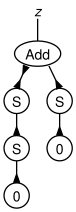

In [3]:
arith = inets.System.parse("""
agent Add 2
agent S 1
agent 0 0
rule Add (z y) >< S (x)
  => z = S (t); x = Add (t y)
rule Add (z y) >< 0
  => z = y
""")
net = inets.Net(arith)
z = net.free()
two = net.make("S", net.make("S", net.make("0")))
one = net.make("S", net.make("0"))
net.wire(net.make("Add", z, one), two)
draw(net, {z: "z"})

Result(reason='normal', interactions=3, counts={}, active_left=0, rounds=0, widest=0)


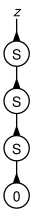

In [4]:
print(net.reduce())
draw(net, {z: "z"})

## The same, photocopied

`retro=True` gives the look of a 1990 figure.

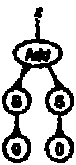

In [5]:
net = inets.Net(arith)
z = net.free()
net.wire(net.make("Add", z, net.make("S", net.make("0"))), net.make("S", net.make("0")))
draw(net, {z: "z"}, retro=True)

## S K K I, by need

The `ski` table marks which ports are outputs, so the result goes on top on its own.
`style="ports"` shows the same net with port numbers.

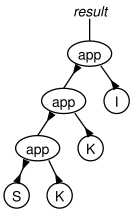

In [6]:
from inets import ski

net = inets.Net(inets.bundled("ski"))
out = net.free()
net.wire(ski.encode(net, ski.parse("```SKKI")), out)
draw(net, {out: "result"})

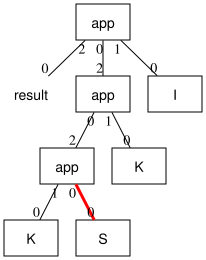

In [7]:
draw(net, {out: "result"}, style="ports")

Result(reason='wanted', interactions=6, counts={'collect': 3, 'contract': 2, 'copy': 1}, active_left=1, rounds=0, widest=0)
I


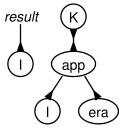

In [8]:
print(net.reduce_by_need(out))
print(ski.show(ski.read_back(net, out)))
draw(net, {out: "result"})